In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Name: CHIMWEMWE JUDAH PONYA
## NO.202407122

## Task 1 

a) 0.5^20 = 9.536743164 x 10^-7(about 0.00000095)
    2^20 = 104875 (about 1.05 x 10^6)
- 0.5^20 is the vanishing gradient case. Each layer shrinks the gradient, so after 20 layers. it is almost zero. Symptom: the gradient norm of the early layers is near zero, their weights barely changes and training loss plateaus or decreases extremely slowly.
- 2^20 is the exploding gradient case. Each layer doubles the gradient, so it grows by about a million times. Symptom: very large gradient norms, loss that spikes or swings wildly and eventually Nan or inf values

b) He variance for Relu
        Var = z / fan_in with fan_in = 100
        Var = 2/100 = 0.02
        Standard deviation = sqrt(0.02) = 0.14142
* Why He often suits Relu better than Xavier *
- Relu sets all negative pre activation to zero, So on average it removes about half of the signal variance at every layer
- He initialization uses the factor 2 in 2/fan_in to compensate for that loss, so activations and gradients keep a roughly stable variane from layer to layer.
- Xavier uses Var = 2/(fan_in + fan_out) (for example 0.01 when fan_in = fan_out = 100) That is about half of He and assume's a roughly linear or symmetric activation such as tanh, with Relu the signal shrinks layer to layer, which matters more as the network gets deeper.
* When Xavier is suitable: with tanh or sigmoid (symmetric activations around zero), with linear layers, or in shallow networks where the difference is small.

c) Diagnosing two curves 
  i) Both trianing and validation loss remain high
   - Diagnosis: underfitting / optimization problem (high bias), The model is not      even fitting the data it sees.
   - One first investigation: Check optimization health before changing              anything else. Log gradient norm of the early layers (near zero suggests        vanishing gradients or dead Relus) and test whether the model can overfit       a tiny batch of data if it cannot the problem is in optimization (              learning rate, initialization, bug ) not generalization.

   ii) Train loss falls while validation loss rises
   - Diagnosis: Overfitting / a generalization problem, the model is memorizing the training set.
   - One first investigation: find the epoch where validation loss is lowest (the point where the gap starts opening) and test one regularizer, for example dropout alone, changing nothing else.

## Task 2: Build a relaible baseline

In [2]:
import copy, platform, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED, BATCH, EPOCHS, LR = 42, 128, 5, 1e-3

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Record the runtime environment (required by the lab)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
print("Seed:", SEED, "| Batch size:", BATCH, "| Epochs:", EPOCHS, "| LR:", LR)

Python: 3.13.7
PyTorch: 2.14.0+cu126
Device: cpu 
Seed: 42 | Batch size: 128 | Epochs: 5 | LR: 0.001


In [3]:
tf = transforms.ToTensor() # converts pixels to floats in [0, 1]
full_train = datasets.FashionMNIST("./data", train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST("./data", train=False, download=True, transform=tf)

labels = full_train.targets.numpy()

train_idx, val_idx = train_test_split(
   np.arange(len(labels)), test_size=0.2, stratify=labels, random_state=SEED)
print(len(train_idx), len(val_idx)) # 48000 12000

train_set, val_set = Subset(full_train, train_idx), Subset(full_train, val_idx)

def get_loaders():
    g = torch.Generator(); g.manual_seed(SEED) # same shuffle order every run
    train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, generator=g)
    val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False)
    return train_loader, val_loader

test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False) # NOT used until Task 4c


48000 12000


In [4]:
train_loader, val_loader = get_loaders()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

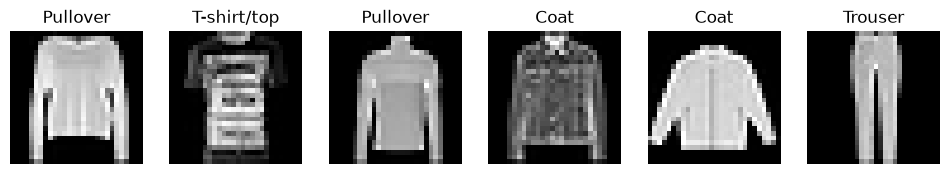

In [5]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax, img, label in zip(axes, images[:10], labels[:10]):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(class_names[label.item()])
    ax.axis("off")
plt.show()

In [6]:
import copy

criterion = nn.CrossEntropyLoss()

def init_weights(m, scheme):
    if isinstance(m, nn.Linear):
        if scheme == "xavier":
            nn.init.xavier_uniform_(m.weight)
        elif scheme == "he":
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")

        nn.init.zeros_(m.bias)


def build_model(init=None, p_drop=0.0):
    set_seed()  # fresh model, same seed every time

    model = nn.Sequential(
        nn.Flatten(),  # 28x28 -> 784
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Dropout(p_drop),

        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Dropout(p_drop),

        nn.Linear(128, 10)  # raw logits
    )

    if init is not None:  # init=None keeps PyTorch's default
        model.apply(lambda m: init_weights(m, init))

    return model.to(device)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total = 0.0
    correct = 0
    n = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        out = model(x)

        total += criterion(out, y).item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)

    return total / n, correct / n


def run_experiment(name, init=None, p_drop=0.0, weight_decay=0.0):

    model = build_model(init, p_drop)

    train_loader, val_loader = get_loaders()

    opt = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        weight_decay=weight_decay
    )

    first_linear = model[1]

    h = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": [],
        "grad_norm": []
    }

    best_acc = 0.0
    best_state = None

    for epoch in range(EPOCHS):

        model.train()

        run_loss = 0.0
        n = 0

        for i, (x, y) in enumerate(train_loader):

            x, y = x.to(device), y.to(device)

            opt.zero_grad()

            loss = criterion(model(x), y)

            loss.backward()

            if i == 0:
                gn = torch.sqrt(
                    sum(
                        p.grad.pow(2).sum()
                        for p in first_linear.parameters()
                    )
                )
                h["grad_norm"].append(gn.item())

            opt.step()

            run_loss += loss.item() * x.size(0)
            n += x.size(0)

        v_loss, v_acc = evaluate(model, val_loader)

        h["train_loss"].append(run_loss / n)
        h["val_loss"].append(v_loss)
        h["val_acc"].append(v_acc)

        if v_acc > best_acc:
            best_acc = v_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"{name} | epoch {epoch+1}: "
            f"train {run_loss/n:.4f} | "
            f"val {v_loss:.4f} | "
            f"val acc {v_acc:.4f} | "
            f"grad norm {h['grad_norm'][-1]:.4f}"
        )

    h["best_val_acc"] = best_acc
    h["best_state"] = best_state

    return model, h

Baseline (default init) | epoch 1: train 0.6136 | val 0.4336 | val acc 0.8442 | grad norm 0.2935
Baseline (default init) | epoch 2: train 0.4134 | val 0.3700 | val acc 0.8684 | grad norm 0.4302
Baseline (default init) | epoch 3: train 0.3633 | val 0.3524 | val acc 0.8749 | grad norm 0.3167
Baseline (default init) | epoch 4: train 0.3313 | val 0.3307 | val acc 0.8821 | grad norm 0.4292
Baseline (default init) | epoch 5: train 0.3103 | val 0.3169 | val acc 0.8864 | grad norm 0.7171
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.0, inplace=False)
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.0, inplace=False)
  (7): Linear(in_features=128, out_features=10, bias=True)
)
Total parameters: 235146
Best validation accuracy: 0.8864


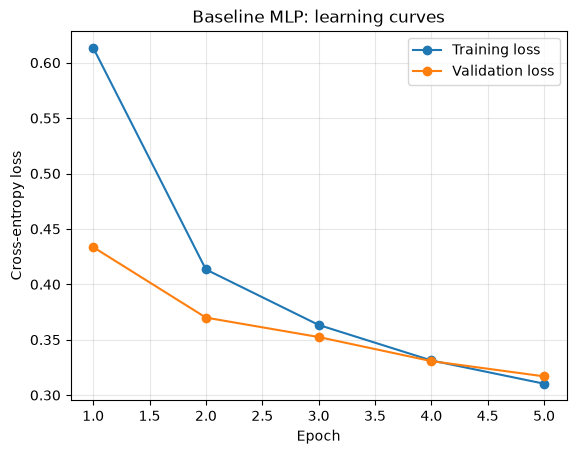

In [7]:
model0, h0 = run_experiment("Baseline (default init)")
print(model0)
print("Total parameters:", sum(p.numel() for p in model0.parameters())) # 235,146
print("Best validation accuracy:", round(h0["best_val_acc"], 4))

ep = range(1, EPOCHS + 1)
plt.plot(ep, h0["train_loss"], marker="o", label="Training loss")
plt.plot(ep, h0["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("Baseline MLP: learning curves"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("task2_curves.png", dpi=150); plt.show()


*why training loss starts higher than validation loss in epoch 1, it’s because training loss is averaged over the whole epoch while the model is still improving. Validation loss is measured once, after the epoch’s updates are done.*

“The network learned, since training loss fell from about 0.61 to 0.31 and validation accuracy reached 88.64% by epoch 5, and it generalized well because validation loss tracked training loss closely with a gap of only about 0.007.”


## Task 3 Fair initialisation experiment

In [8]:
model_x, h_x = run_experiment("Run X (Xavier)", init="xavier")
model_h, h_h = run_experiment("Run H (He)",  init="he")

print(f"{'Run':<16}{'Best val acc':>14}{'Epoch-1 train loss':>20}{'Epoch-1 grad norm':>20}")
for name, h in [("X: Xavier", h_x), ("H: He", h_h)]:
    print(f"{name:<16}{h['best_val_acc']:>14.4f}{h['train_loss'][0]:>20.4f}{h['grad_norm'][0]:>20.4f}")

Run X (Xavier) | epoch 1: train 0.5443 | val 0.4036 | val acc 0.8563 | grad norm 1.6069
Run X (Xavier) | epoch 2: train 0.3901 | val 0.3610 | val acc 0.8721 | grad norm 0.5301
Run X (Xavier) | epoch 3: train 0.3424 | val 0.3437 | val acc 0.8782 | grad norm 0.5256
Run X (Xavier) | epoch 4: train 0.3122 | val 0.3258 | val acc 0.8805 | grad norm 0.5118
Run X (Xavier) | epoch 5: train 0.2964 | val 0.3164 | val acc 0.8852 | grad norm 0.9533
Run H (He) | epoch 1: train 0.5255 | val 0.3952 | val acc 0.8608 | grad norm 2.0738
Run H (He) | epoch 2: train 0.3835 | val 0.3509 | val acc 0.8735 | grad norm 0.4748
Run H (He) | epoch 3: train 0.3362 | val 0.3319 | val acc 0.8844 | grad norm 0.5020
Run H (He) | epoch 4: train 0.3083 | val 0.3291 | val acc 0.8810 | grad norm 0.5457
Run H (He) | epoch 5: train 0.2901 | val 0.3109 | val acc 0.8875 | grad norm 1.0275
Run               Best val acc  Epoch-1 train loss   Epoch-1 grad norm
X: Xavier               0.8852              0.5443              1.606

“Yes, but only weakly. He normal beat Xavier uniform on best validation accuracy (88.75% vs 88.52%), first-epoch loss (0.5255 vs 0.5443), and final validation loss (0.3109 vs 0.3164), and its first-layer gradient norm was larger at epoch 1 (2.07 vs 1.61). This is consistent with He compensating for ReLU zeroing half of the activations. However, the accuracy gap is only 0.23 percentage points, which is within the run-to-run noise I would expect from a single seed. The network is also shallow (three Linear layers), where the vanishing-signal problem that He fixes is small. So my evidence supports the prediction in direction, but is not strong enough to claim He is clearly better.”

## Task 4: Controlled ablation

In [9]:
# Direct check on the Dropout layer
drop = nn.Dropout(0.25)
x = torch.ones(10000)
drop.train(); y_train = drop(x)
print("Train mode: fraction zeroed =", (y_train == 0).float().mean().item()) # ~0.25
print("Train mode: kept values scaled to", y_train[y_train != 0][0].item()) # 1/(1-0.25) = 1.3333
drop.eval(); y_eval = drop(x)
print("Eval mode: identical to input?", torch.equal(x, y_eval)) # True

# Check on the full model
m = build_model("he", 0.25)
img = torch.rand(1, 1, 28, 28).to(device)
m.train(); print("train(): two passes equal?", torch.equal(m(img), m(img))) # False (random masks)
m.eval(); print("eval(): two passes equal?", torch.equal(m(img), m(img))) # True

Train mode: fraction zeroed = 0.25380000472068787
Train mode: kept values scaled to 1.3333333730697632
Eval mode: identical to input? True
train(): two passes equal? False
eval(): two passes equal? True


In [10]:
model_B, h_B = run_experiment("B: baseline", init="he", p_drop=0.0, weight_decay=0.0)
model_A, h_A = run_experiment("A: dropout", init="he", p_drop=0.25, weight_decay=0.0)
model_C, h_C = run_experiment("C: L2", init="he", p_drop=0.0, weight_decay=1e-4)

results = {"B: baseline": h_B, "A: dropout": h_A, "C: L2": h_C}
print(f"{'Run':<14}{'Best val acc':>14}{'Final val loss':>16}")
for k, h in results.items():
    print(f"{k:<14}{h['best_val_acc']:>14.4f}{h['val_loss'][-1]:>16.4f}")

B: baseline | epoch 1: train 0.5255 | val 0.3952 | val acc 0.8608 | grad norm 2.0738
B: baseline | epoch 2: train 0.3835 | val 0.3509 | val acc 0.8735 | grad norm 0.4748
B: baseline | epoch 3: train 0.3362 | val 0.3319 | val acc 0.8844 | grad norm 0.5020
B: baseline | epoch 4: train 0.3083 | val 0.3291 | val acc 0.8810 | grad norm 0.5457
B: baseline | epoch 5: train 0.2901 | val 0.3109 | val acc 0.8875 | grad norm 1.0275
A: dropout | epoch 1: train 0.6312 | val 0.4097 | val acc 0.8500 | grad norm 2.3826
A: dropout | epoch 2: train 0.4456 | val 0.3826 | val acc 0.8608 | grad norm 0.7361
A: dropout | epoch 3: train 0.3945 | val 0.3535 | val acc 0.8756 | grad norm 0.6371
A: dropout | epoch 4: train 0.3718 | val 0.3418 | val acc 0.8746 | grad norm 0.5965
A: dropout | epoch 5: train 0.3534 | val 0.3207 | val acc 0.8828 | grad norm 0.7207
C: L2 | epoch 1: train 0.5258 | val 0.3945 | val acc 0.8610 | grad norm 2.0738
C: L2 | epoch 2: train 0.3839 | val 0.3594 | val acc 0.8708 | grad norm 0.48

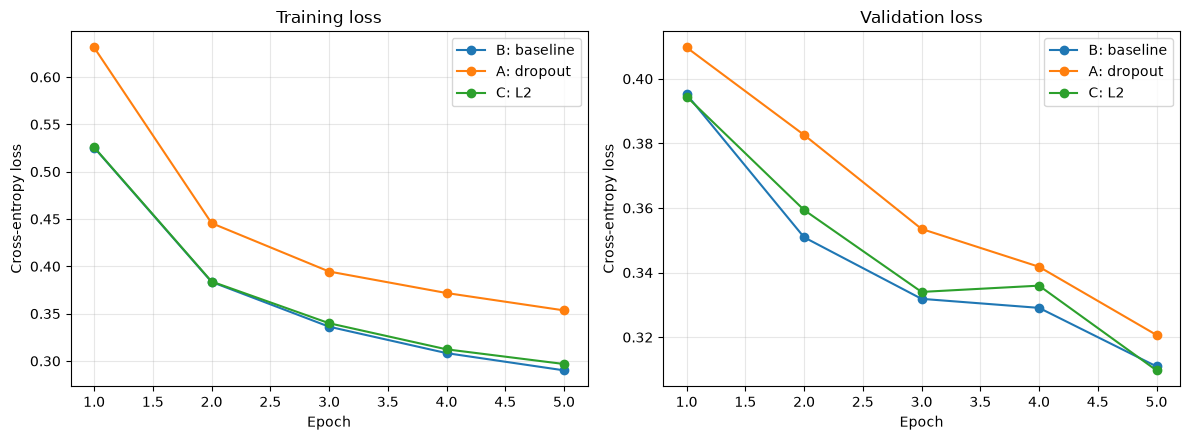

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, h in results.items():
   ax[0].plot(ep, h["train_loss"], marker="o", label=k)
   ax[1].plot(ep, h["val_loss"], marker="o", label=k)
ax[0].set_title("Training loss"); ax[1].set_title("Validation loss")
for a in ax:
    a.set_xlabel("Epoch"); a.set_ylabel("Cross-entropy loss"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("task4_overlay.png", dpi=150); plt.show()

- Fastest optimizer (training loss): the run whose training curve is lowest and drops fastest. This is usually
B (baseline), because it has no regularization slowing it down. Dropout (A) usually shows a higher training
loss because random units are switched off during training, so it is harder to fit.
- Best generalizer (validation): the run with the lowest validation loss and highest validation accuracy.
Dropout (A) often has the smallest gap between training and validation loss. L2 at 1e-4 (C) is usually very
close to the baseline because the penalty is small and training is only 5 epochs. Report whatever your
numbers show.
- Evidence of overfitting: look for training loss still falling while validation loss flattens or rises, and for a
growing gap between the two curves. This is most likely in B, around epochs 3 to 5.
- Why the lowest training loss may not win: training loss measures how well the model fits the data it has
already seen, which can be achieved by memorizing it. What matters for the retail application is performance
on new images, which validation loss and accuracy estimate. A model can have the lowest training loss yet
the highest validation loss.

In [12]:
best_name = max(results, key=lambda k: results[k]["best_val_acc"]) # chosen using VALIDATION only
print("Selected run:", best_name)

final_models = {"B: baseline": model_B, "A: dropout": model_A, "C: L2": model_C}
final_model = final_models[best_name]
final_model.load_state_dict(results[best_name]["best_state"]) # best-validation weights

test_loss, test_acc = evaluate(final_model, test_loader) # the ONLY test evaluation
print(f"Test loss {test_loss:.4f} | Test accuracy {test_acc:.4f}")

Selected run: B: baseline
Test loss 0.3424 | Test accuracy 0.8757


Selected run: baseline, chosen because it had the highest validation accuracy and the near lowest final validation loss 
- limitation, Data shift: Fashion-MNIST images are 28x28, grayscale, centered, with plain backgrounds. Photos taken
with a phone are colour, higher resolution, with clutter, different lighting, angles and partial views, so real
accuracy would be lower than the test score.

## Task 5 : Engineering decisions

1) NaN loss after one large update: where to clip, and one other check
• Apply gradient clipping after loss.backward() and before optimizer.step(), because the gradients exist
only after backward and the step is what turns a huge gradient into a destructive weight update:

loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()

• Another sensible first check: lower the learning rate (a too-large learning rate is the most common cause), or
check the input data and labels for NaN/inf values.

2) Very small batches: Batch Norm vs Layer Norm

• Batch Normalization computes the mean and variance across the batch. With very small batches those statistics are noisy (and with batch size 1 they are meaningless), so training becomes unstable and the
running statistics used at evaluation time can differ from what the model saw in training.

• Layer Normalization computes the statistics across the features of each single sample, so it does not depend on other samples in the batch.

• Layer Normalization is batch-size independent.

3) Residual block equation and why the shortcut helps gradients
   
• Equation: y = F(x) + x, where F(x) is the output of the block's layers (for example two weight layers with activations). If the dimensions differ, use y = F(x) + W_s x.

• Gradient: dy/dx = dF/dx + I (the identity matrix). Even if dF/dx becomes very small, the identity term gives the gradient a direct path backward, so it does not vanish as it passes through many blocks. The block only has to learn the residual F(x), which is easier than learning a full mapping, so very deep networks become
trainable.

4) Augmentation for Fashion-MNIST, and avoiding leakage

• Valid augmentation: a random horizontal flip (most clothing is roughly left-right symmetric), or small random translation or rotation (a few degrees) to mimic slight shifts in position.

• Invalid or risky: a vertical flip or a large rotation (such as 90 or 180 degrees). Clothes are not photographed upside down, so this creates unrealistic images and can confuse similar classes. Heavy random erasing is also risky because it can hide the features that distinguish a shirt from a pullover.

• Avoiding leakage: split the data into train/validation/test first, then apply augmentation only to the training set. Use separate dataset objects: the training dataset gets a transform that includes augmentation, while the validation and test datasets use only ToTensor(). Never augment before splitting, because augmented
copies of the same image could land in both training and validation sets and inflate the scores. In the code
above, the Task 4 comparison keeps augmentation off for exactly this reason.

In [13]:
# Per-class validation accuracy for the selected model (validation set only; test set stays untouched until Task 4c)
model = final_model
model.eval()
correct, total = torch.zeros(10), torch.zeros(10)
with torch.no_grad():
    for x, y in val_loader:
        pred = model(x.to(device)).argmax(1).cpu()
        for c in range(10):
            m = y == c
            total[c] += m.sum()
            correct[c] += (pred[m] == c).sum()
for c in range(10):
    print(f"{class_names[c]:<12} {100*correct[c]/total[c]:5.1f}%")


T-shirt/top   89.2%
Trouser       97.3%
Pullover      85.3%
Dress         89.8%
Coat          83.2%
Sandal        96.2%
Shirt         57.0%
Sneaker       96.2%
Bag           97.3%
Ankle boot    95.8%


In [14]:
import io
import numpy as np
import torch
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image, ImageOps

# ---- 1. Use the model selected on validation in Task 4 ----
model = final_model
device = next(model.parameters()).device
model.eval()

# `tf` (ToTensor only, no Normalize) and `class_names` come from the Task 2 cells and match training.

# ---- 2. Upload and classify ----
auto_box = widgets.Checkbox(value=True, description="Auto-invert (for light backgrounds)")
flip_box = widgets.Checkbox(value=False, description="Flip horizontally (toe should point left)")
uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Choose picture")
out = widgets.Output()

def prepare(img, auto=True, flip=False):
    """Make an uploaded photo look like a Fashion-MNIST image:
    bright object, tightly cropped, filling the frame, centred on a black 28x28 canvas."""
    img = ImageOps.exif_transpose(img)   # fix phone-photo rotation
    img = img.convert("L")
    arr = np.asarray(img, dtype=np.float32)

    # background = median of the border pixels (more robust than one corner pixel)
    border = np.concatenate([arr[0, :], arr[-1, :], arr[:, 0], arr[:, -1]])
    bg = np.median(border)

    # object brightness = how different each pixel is from the background
    # (bright object on black for both light and dark backgrounds)
    diff = np.abs(arr - bg)
    mask = diff > 30
    if mask.any():
        ys, xs = np.where(mask)
        diff = diff[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
        mask = mask[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    diff = diff * mask
    diff = 255 * diff / max(diff.max(), 1)

    obj = Image.fromarray(diff.astype(np.uint8))
    if flip:
        obj = ImageOps.mirror(obj)

    obj = ImageOps.contain(obj, (28, 28), Image.LANCZOS)   # Fashion-MNIST items touch the frame edge
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(obj, ((28 - obj.width) // 2, (28 - obj.height) // 2))
    return canvas

def classify(change):
    files = uploader.value
    if not files:
        return
    f = files[0] if isinstance(files, (tuple, list)) else list(files.values())[0]
    with out:
        clear_output()
        img = prepare(Image.open(io.BytesIO(bytes(f["content"]))), auto_box.value, flip_box.value)

        x = tf(img).unsqueeze(0).to(device)
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(x), dim=1)[0].cpu()
        top = probs.topk(3)

        plt.figure(figsize=(2, 2))
        plt.imshow(img, cmap="gray")
        plt.title(f"{class_names[top.indices[0].item()]} ({top.values[0].item()*100:.1f}%)")
        plt.axis("off")
        plt.show()

        for p, i in zip(top.values, top.indices):
            print(f"{class_names[i.item()]:<12} {p.item()*100:5.1f}%")

    uploader.value = ()   # reset so you can upload the same file again

uploader.observe(classify, names="value")
display(auto_box, flip_box, uploader, out)


Checkbox(value=True, description='Auto-invert (for light backgrounds)')

Checkbox(value=False, description='Flip horizontally (toe should point left)')

FileUpload(value=(), accept='image/*', description='Choose picture')

Output()